In [1]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries successfully imported.")
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


Libraries successfully imported.
PyTorch: 2.15.0+cpu
NumPy: 2.5.4
Pandas: 3.1.1


In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

AUDIO_DIR = PROJECT_ROOT / "dataset" / "audio"
BEATMAP_DIR = PROJECT_ROOT / "dataset" / "beatmap" / "4keys"

print("PROJECT ROOT:", PROJECT_ROOT)
print("AUDIO DIRECTORY:", AUDIO_DIR)
print("BEATMAP DIRECTORY:", BEATMAP_DIR)

assert AUDIO_DIR.exists(), "Audio directory not found!"
assert BEATMAP_DIR.exists(), "Beatmap directory not found!"

print("\nDataset directories successfully located.")


PROJECT ROOT: C:\Users\63906\TRACERS
AUDIO DIRECTORY: C:\Users\63906\TRACERS\dataset\audio
BEATMAP DIRECTORY: C:\Users\63906\TRACERS\dataset\beatmap\4keys

Dataset directories successfully located.


In [3]:
audio_files = sorted(AUDIO_DIR.glob("*.pt"))
beatmap_files = sorted(BEATMAP_DIR.glob("*.pt"))

audio_count = len(audio_files)
beatmap_count = len(beatmap_files)

inventory = pd.DataFrame({
    "Dataset Component": ["Audio", "Beatmap (4-key)"],
    "Number of Files": [audio_count, beatmap_count]
})

display(inventory)

print("Total audio files:", audio_count)
print("Total beatmap files:", beatmap_count)
print("Beatmaps per audio file:", round(beatmap_count / audio_count, 2))


,Dataset Component,Number of Files
0,Audio,399
1,Beatmap (4-key),1126


Total audio files: 399
Total beatmap files: 1126
Beatmaps per audio file: 2.82


In [4]:
audio_ids = {file.stem for file in audio_files}

# Extract song IDs from beatmap filenames.
# Format: song_id-difficulty-4.pt

beatmap_song_ids = {
    file.stem.rsplit("-", 2)[0]
    for file in beatmap_files
}

matched_ids = audio_ids.intersection(beatmap_song_ids)

audio_without_beatmap = audio_ids - beatmap_song_ids
beatmap_without_audio = beatmap_song_ids - audio_ids

print("AUDIO-BEATMAP MATCHING RESULTS")
print("=" * 40)

print("Audio song IDs:", len(audio_ids))
print("Beatmap song IDs:", len(beatmap_song_ids))
print("Matched song IDs:", len(matched_ids))
print("Audio without beatmap:", len(audio_without_beatmap))
print("Beatmap without audio:", len(beatmap_without_audio))

print("\nMatching percentage:",
      round(len(matched_ids) / len(audio_ids) * 100, 2), "%")


AUDIO-BEATMAP MATCHING RESULTS
Audio song IDs: 399
Beatmap song IDs: 375
Matched song IDs: 375
Audio without beatmap: 24
Beatmap without audio: 0

Matching percentage: 93.98 %


In [5]:
audio_metadata = []
beatmap_metadata = []

def load_tensor_file(path):
    return torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

# Inspect audio files
for path in audio_files:

    data = load_tensor_file(path)

    specs = data["specs"]

    audio_metadata.append({
        "song_id": path.stem,
        "specs_shape": tuple(specs.shape),
        "frames": specs.shape[1],
        "specs_dtype": str(specs.dtype),
        "beat_phase_dtype": str(data["beat_phase"].dtype),
        "beat_num_dtype": str(data["beat_num"].dtype)
    })

# Inspect beatmap files
for path in beatmap_files:

    data = load_tensor_file(path)

    beatmap_metadata.append({
        "filename": path.name,
        "song_id": path.stem.rsplit("-", 2)[0],
        "actions_shape": tuple(data["actions"].shape),
        "onsets_shape": tuple(data["onsets"].shape),
        "beatmap_shape": tuple(data["beatmap"].shape),
        "difficulty": data["difficulty"]
    })

audio_df = pd.DataFrame(audio_metadata)
beatmap_df = pd.DataFrame(beatmap_metadata)

print("AUDIO TENSOR SUMMARY")
display(audio_df.head())

print("BEATMAP TENSOR SUMMARY")
display(beatmap_df.head())


AUDIO TENSOR SUMMARY


,song_id,specs_shape,frames,specs_dtype,beat_phase_dtype,beat_num_dtype
0,1003093,"(3, 9102, 80)",9102,torch.float32,torch.int32,torch.int32
1,1003217,"(3, 13957, 80)",13957,torch.float32,torch.int32,torch.int32
2,1008060,"(3, 23890, 80)",23890,torch.float32,torch.int32,torch.int32
3,1008095,"(3, 13005, 80)",13005,torch.float32,torch.int32,torch.int32
4,1010916,"(3, 9382, 80)",9382,torch.float32,torch.int32,torch.int32


BEATMAP TENSOR SUMMARY


,filename,song_id,actions_shape,onsets_shape,beatmap_shape,difficulty
0,1003093-108-4.pt,1003093,"(9102,)","(9102,)","(267, 3)",5
1,1003093-172-4.pt,1003093,"(9102,)","(9102,)","(452, 3)",9
2,1003093-216-4.pt,1003093,"(9102,)","(9102,)","(752, 3)",11
3,1003093-314-4.pt,1003093,"(9102,)","(9102,)","(1102, 3)",16
4,1003217-148-4.pt,1003217,"(13957,)","(13957,)","(534, 3)",7


In [6]:

# ==========================================
# 6.1 AUDIO DATA INTEGRITY
# ==========================================

audio_integrity = []

for path in audio_files:
    try:
        data = load_tensor_file(path)

        required_keys = ["specs", "beat_phase", "beat_num"]
        missing_keys = [k for k in required_keys if k not in data]

        errors = []

        if missing_keys:
            errors.append(f"Missing keys: {missing_keys}")
        
        if not missing_keys:
            specs = data["specs"]
            phase = data["beat_phase"]
            beat_num = data["beat_num"]

            if specs.ndim != 3 or specs.shape[0] != 3 or specs.shape[2] != 80:
                errors.append("Invalid specs shape")

            if phase.ndim != 1:
                errors.append("Invalid beat_phase dimensions")

            if beat_num.ndim != 1:
                errors.append("Invalid beat_num dimensions")

            if specs.ndim == 3:
                frames = specs.shape[1]

                if phase.ndim == 1 and len(phase) != frames:
                    errors.append("beat_phase length mismatch")

                if beat_num.ndim == 1 and len(beat_num) != frames:
                    errors.append("beat_num length mismatch")

            for key in required_keys:
                tensor = data[key]

                if isinstance(tensor, torch.Tensor):
                    if tensor.is_floating_point() or tensor.is_complex():
                        if not torch.isfinite(tensor).all():
                            errors.append(f"Non-finite values in {key}")

        audio_integrity.append({
            "filename": path.name,
            "valid": len(errors) == 0,
            "issues": "; ".join(errors)
        })

    except Exception as e:
        audio_integrity.append({
            "filename": path.name,
            "valid": False,
            "issues": str(e)
        })

audio_integrity_df = pd.DataFrame(audio_integrity)

print("AUDIO INTEGRITY RESULTS")
print("=" * 40)
print("Total files:", len(audio_integrity_df))
print("Valid files:", audio_integrity_df["valid"].sum())
print("Invalid files:", (~audio_integrity_df["valid"]).sum())

display(audio_integrity_df[audio_integrity_df["valid"] == False].head(10))


AUDIO INTEGRITY RESULTS
Total files: 399
Valid files: 399
Invalid files: 0


,filename,valid,issues


In [7]:

# ==========================================
# 6.2 BEATMAP DATA INTEGRITY
# ==========================================

beatmap_integrity = []

for path in beatmap_files:
    try:
        data = load_tensor_file(path)

        required_keys = ["actions", "onsets", "beatmap", "difficulty"]
        missing_keys = [k for k in required_keys if k not in data]

        errors = []

        if missing_keys:
            errors.append(f"Missing keys: {missing_keys}")

        if not missing_keys:
            actions = data["actions"]
            onsets = data["onsets"]
            beatmap = data["beatmap"]

            if actions.ndim != 1:
                errors.append("Invalid actions dimensions")

            if onsets.ndim != 1:
                errors.append("Invalid onsets dimensions")

            if actions.ndim == 1 and onsets.ndim == 1:
                if len(actions) != len(onsets):
                    errors.append("Actions/onsets length mismatch")

            if beatmap.ndim != 2 or beatmap.shape[1] != 3:
                errors.append("Invalid beatmap shape")

            for key in ["actions", "onsets", "beatmap"]:
                tensor = data[key]

                if isinstance(tensor, torch.Tensor):
                    if tensor.is_floating_point() or tensor.is_complex():
                        if not torch.isfinite(tensor).all():
                            errors.append(f"Non-finite values in {key}")

        beatmap_integrity.append({
            "filename": path.name,
            "valid": len(errors) == 0,
            "issues": "; ".join(errors)
        })

    except Exception as e:
        beatmap_integrity.append({
            "filename": path.name,
            "valid": False,
            "issues": str(e)
        })

beatmap_integrity_df = pd.DataFrame(beatmap_integrity)

print("BEATMAP INTEGRITY RESULTS")
print("=" * 40)
print("Total files:", len(beatmap_integrity_df))
print("Valid files:", beatmap_integrity_df["valid"].sum())
print("Invalid files:", (~beatmap_integrity_df["valid"]).sum())

display(beatmap_integrity_df[beatmap_integrity_df["valid"] == False].head(10))


BEATMAP INTEGRITY RESULTS
Total files: 1126
Valid files: 1126
Invalid files: 0


,filename,valid,issues


In [8]:

# ==========================================
# 6.3 AUDIO-BEATMAP FRAME ALIGNMENT
# ==========================================

audio_frame_lookup = dict(
    zip(audio_df["song_id"], audio_df["frames"])
)

alignment_results = []

for _, row in beatmap_df.iterrows():

    song_id = row["song_id"]
    beatmap_frames = row["actions_shape"][0]

    audio_frames = audio_frame_lookup.get(song_id)

    if audio_frames is None:
        status = "Missing audio"
    elif audio_frames == beatmap_frames:
        status = "Aligned"
    else:
        status = "Frame mismatch"

    alignment_results.append({
        "song_id": song_id,
        "filename": row["filename"],
        "audio_frames": audio_frames,
        "beatmap_frames": beatmap_frames,
        "status": status
    })

alignment_df = pd.DataFrame(alignment_results)

print("AUDIO-BEATMAP ALIGNMENT")
print("=" * 40)

display(alignment_df["status"].value_counts().to_frame("Count"))

print("\nSample alignment results:")
display(alignment_df.head(10))


AUDIO-BEATMAP ALIGNMENT


,Count
status,
Aligned,1126



Sample alignment results:


,song_id,filename,audio_frames,beatmap_frames,status
0,1003093,1003093-108-4.pt,9102,9102,Aligned
1,1003093,1003093-172-4.pt,9102,9102,Aligned
2,1003093,1003093-216-4.pt,9102,9102,Aligned
3,1003093,1003093-314-4.pt,9102,9102,Aligned
4,1003217,1003217-148-4.pt,13957,13957,Aligned
5,1003217,1003217-262-4.pt,13957,13957,Aligned
6,1003217,1003217-359-4.pt,13957,13957,Aligned
7,1008060,1008060-202-4.pt,23890,23890,Aligned
8,1008060,1008060-329-4.pt,23890,23890,Aligned
9,1008095,1008095-235-4.pt,13005,13005,Aligned


In [9]:

# ==========================================
# 8. AUDIO STATISTICAL ANALYSIS
# ==========================================

audio_statistics = []

for path in audio_files:

    data = load_tensor_file(path)
    specs = data["specs"].float()

    for channel in range(specs.shape[0]):

        channel_data = specs[channel]

        audio_statistics.append({
            "song_id": path.stem,
            "channel": channel + 1,
            "mean": channel_data.mean().item(),
            "std": channel_data.std().item(),
            "min": channel_data.min().item(),
            "max": channel_data.max().item(),
            "median": channel_data.median().item()
        })

audio_stats_df = pd.DataFrame(audio_statistics)

print("AUDIO FEATURE STATISTICS")
display(audio_stats_df.groupby("channel")[
    ["mean", "std", "min", "max", "median"]
].agg(["mean", "std", "min", "max"]).round(4))


AUDIO FEATURE STATISTICS


mean                             std                           \
           mean     std     min     max    mean     std     min      max   
channel                                                                    
1        2.4846  1.3969 -9.5312  4.7052  5.1692  2.8028  2.0409  16.1356   
2        3.9357  1.3764 -7.7234  6.1542  5.0949  2.8010  1.9675  16.0968   
3        5.4407  1.3287 -6.2973  7.6476  4.9737  2.7877  1.8945  16.0238   

             min                                 max                   \
            mean      std      min      max     mean     std      min   
channel                                                                 
1       -53.6200  19.9572 -77.9275 -14.1853  10.2235  0.4729   7.4885   
2       -48.8209  19.5881 -68.6611 -12.1486  11.6447  0.4917   8.9664   
3       -44.9870  21.1341 -67.1955 -10.5173  12.9986  0.5182  10.2808   

                  median                          
             max    mean     std     min     max  
channel                                           
1        12.0988  3.2783  1.1797 -8.7484  4.9630  
2        13.8365  4.7301  1.1489 -7.3988  6.4051  
3        15.0488  6.2226  1.0884 -5.9753  7.8614

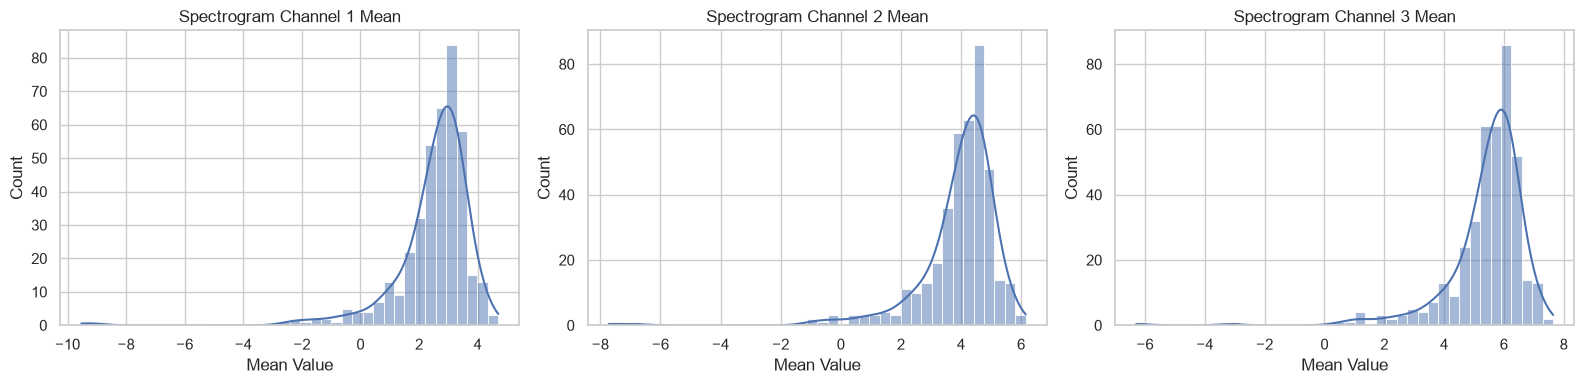

In [10]:

# ==========================================
# 8.1 AUDIO FEATURE DISTRIBUTIONS
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for channel in [1, 2, 3]:

    subset = audio_stats_df[
        audio_stats_df["channel"] == channel
    ]

    sns.histplot(
        data=subset,
        x="mean",
        kde=True,
        ax=axes[channel - 1]
    )

    axes[channel - 1].set_title(
        f"Spectrogram Channel {channel} Mean"
    )

    axes[channel - 1].set_xlabel("Mean Value")

plt.tight_layout()
plt.show()


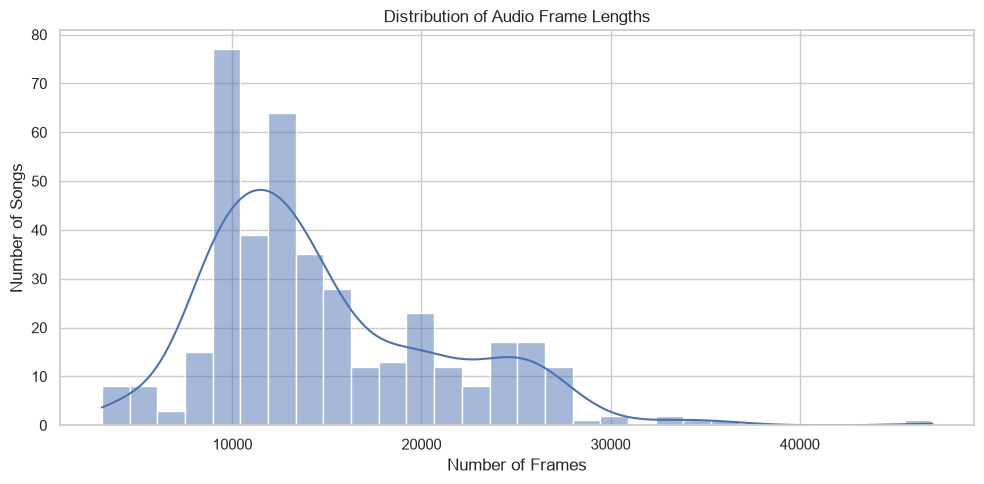

AUDIO FRAME LENGTH SUMMARY


,frames
count,399.000000
mean,14804.877193
std,6358.283639
min,3107.000000
25%,10027.000000
50%,12785.000000
75%,19007.000000
max,47017.000000


In [11]:

# ==========================================
# 8.2 AUDIO FRAME LENGTH DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 5))

sns.histplot(
    data=audio_df,
    x="frames",
    bins=30,
    kde=True
)

plt.title("Distribution of Audio Frame Lengths")
plt.xlabel("Number of Frames")
plt.ylabel("Number of Songs")

plt.tight_layout()
plt.show()

print("AUDIO FRAME LENGTH SUMMARY")

display(audio_df["frames"].describe().to_frame())


In [12]:

# ==========================================
# 9. BEATMAP STATISTICAL ANALYSIS
# ==========================================

print("BEATMAP EVENT STATISTICS")

display(
    beatmap_df[["difficulty"]].describe()
)

beatmap_df["event_count"] = beatmap_df[
    "beatmap_shape"
].apply(lambda x: x[0])

print("\nBEATMAP EVENT COUNT SUMMARY")

display(
    beatmap_df["event_count"].describe().to_frame()
)


BEATMAP EVENT STATISTICS


,difficulty
count,1126.000000
mean,12.355240
std,4.089651
min,4.000000
25%,9.000000
50%,12.000000
75%,16.000000
max,20.000000



BEATMAP EVENT COUNT SUMMARY


,event_count
count,1126.000000
mean,1014.923623
std,631.501874
min,91.000000
25%,541.250000
50%,878.500000
75%,1306.500000
max,3982.000000


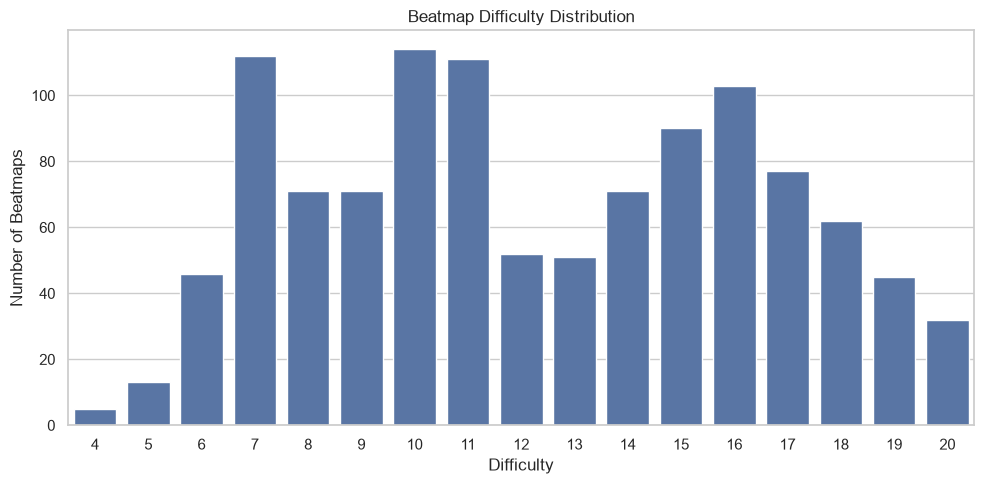

In [13]:

# ==========================================
# 9.1 DIFFICULTY DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 5))

sns.countplot(
    data=beatmap_df,
    x="difficulty"
)

plt.title("Beatmap Difficulty Distribution")
plt.xlabel("Difficulty")
plt.ylabel("Number of Beatmaps")

plt.tight_layout()
plt.show()


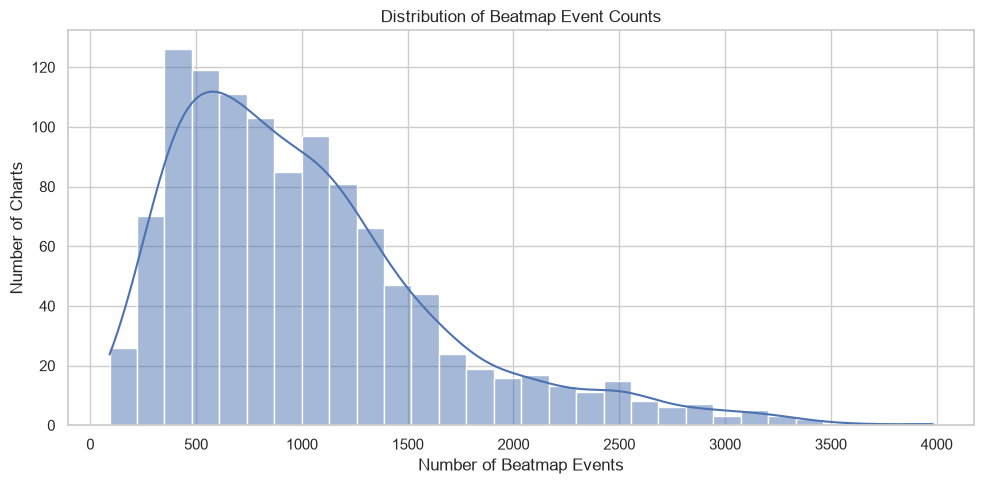

In [14]:

# ==========================================
# 9.2 BEATMAP EVENT COUNT DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 5))

sns.histplot(
    data=beatmap_df,
    x="event_count",
    bins=30,
    kde=True
)

plt.title("Distribution of Beatmap Event Counts")
plt.xlabel("Number of Beatmap Events")
plt.ylabel("Number of Charts")

plt.tight_layout()
plt.show()


In [15]:

# ==========================================
# 10. ACTION AND ONSET DISTRIBUTION
# ==========================================

action_counter = Counter()
onset_counter = Counter()

for path in beatmap_files:

    data = load_tensor_file(path)

    actions = data["actions"].cpu().numpy()
    onsets = data["onsets"].cpu().numpy()

    action_counter.update(actions.tolist())
    onset_counter.update(onsets.tolist())

action_distribution = pd.DataFrame(
    action_counter.items(),
    columns=["Action Value", "Frequency"]
).sort_values("Action Value")

onset_distribution = pd.DataFrame(
    onset_counter.items(),
    columns=["Onset Value", "Frequency"]
).sort_values("Onset Value")

print("ACTION VALUE DISTRIBUTION")
display(action_distribution)

print("ONSET VALUE DISTRIBUTION")
display(onset_distribution)


ACTION VALUE DISTRIBUTION


,Action Value,Frequency
0,0,15296022
4,1,86231
7,2,7313
131,3,2782
6,4,121868
...,...,...
101,251,27
157,252,129
233,253,34
234,254,18


ONSET VALUE DISTRIBUTION


,Onset Value,Frequency
0,0,15296022
1,1,761782


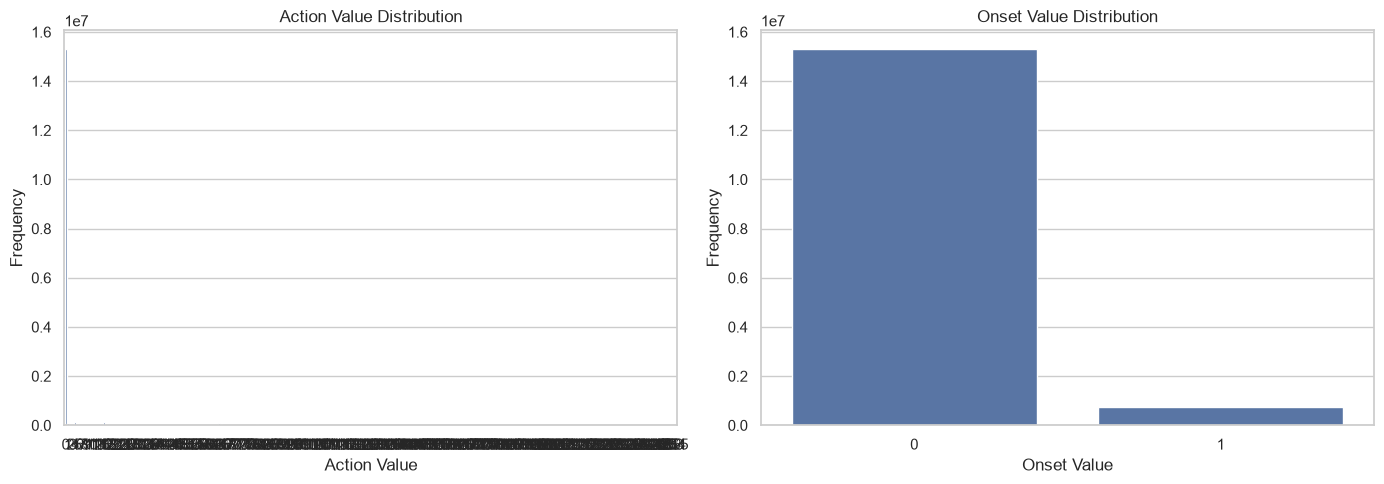

In [16]:

# ==========================================
# 10.1 ACTION AND ONSET VISUALIZATION
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=action_distribution,
    x="Action Value",
    y="Frequency",
    ax=axes[0]
)

axes[0].set_title("Action Value Distribution")
axes[0].set_xlabel("Action Value")
axes[0].set_ylabel("Frequency")

sns.barplot(
    data=onset_distribution,
    x="Onset Value",
    y="Frequency",
    ax=axes[1]
)

axes[1].set_title("Onset Value Distribution")
axes[1].set_xlabel("Onset Value")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


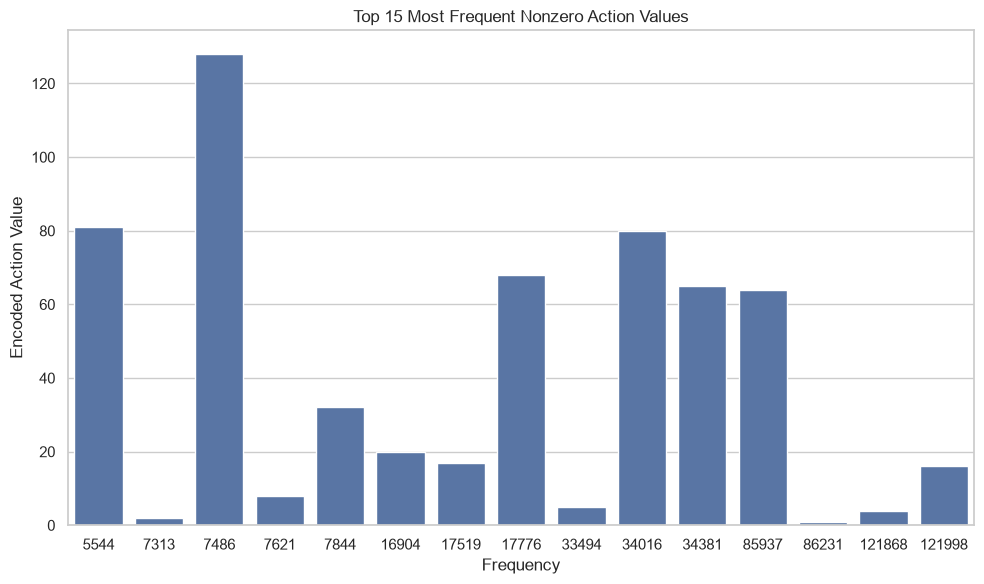

In [17]:

# ==========================================
# 10.2 IMPROVED ACTION DISTRIBUTION
# ==========================================

# Display the 15 most frequent nonzero action values

action_nonzero = action_distribution[
    action_distribution["Action Value"] != 0
].copy()

top_actions = action_nonzero.nlargest(
    15, "Frequency"
).sort_values("Frequency", ascending=True)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_actions,
    x="Frequency",
    y="Action Value"
)

plt.title("Top 15 Most Frequent Nonzero Action Values")
plt.xlabel("Frequency")
plt.ylabel("Encoded Action Value")

plt.tight_layout()
plt.show()


In [18]:

# ==========================================
# 10.3 ACTION AND ONSET PERCENTAGES
# ==========================================

action_distribution["Percentage"] = (
    action_distribution["Frequency"] /
    action_distribution["Frequency"].sum() * 100
)

onset_distribution["Percentage"] = (
    onset_distribution["Frequency"] /
    onset_distribution["Frequency"].sum() * 100
)

print("ACTION DISTRIBUTION")
display(action_distribution.sort_values(
    "Frequency", ascending=False
).head(15))

print("ONSET DISTRIBUTION")
display(onset_distribution)


ACTION DISTRIBUTION


,Action Value,Frequency,Percentage
0,0,15296022,95.256001
5,16,121998,0.759743
6,4,121868,0.758933
4,1,86231,0.537004
1,64,85937,0.535173
37,65,34381,0.214108
12,80,34016,0.211835
30,5,33494,0.208584
48,68,17776,0.110700
36,17,17519,0.109100


ONSET DISTRIBUTION


,Onset Value,Frequency,Percentage
0,0,15296022,95.256001
1,1,761782,4.743999


In [19]:

# ==========================================
# 11. DECODED FOUR-LANE ACTION ANALYSIS
# ==========================================

from tracers.datasets.dataset import decode_4key_actions

lane_state_counts = np.zeros((4, 4), dtype=np.int64)

for path in beatmap_files:
    data = load_tensor_file(path)

    actions = data["actions"].long()

    decoded = decode_4key_actions(actions)

    for lane in range(4):
        for state in range(4):
            lane_state_counts[lane, state] += (
                decoded[:, lane] == state
            ).sum().item()

lane_names = ["Lane 1", "Lane 2", "Lane 3", "Lane 4"]
state_names = [
    "Empty",
    "Normal Note",
    "Long Note Start",
    "Long Note End"
]

lane_state_df = pd.DataFrame(
    lane_state_counts,
    index=lane_names,
    columns=state_names
)

print("DECODED LANE STATE DISTRIBUTION")
display(lane_state_df)


DECODED LANE STATE DISTRIBUTION


,Empty,Normal Note,Long Note Start,Long Note End
Lane 1,15775414,215478,33456,33456
Lane 2,15770067,227173,30282,30282
Lane 3,15768453,227179,31086,31086
Lane 4,15774478,215222,34052,34052


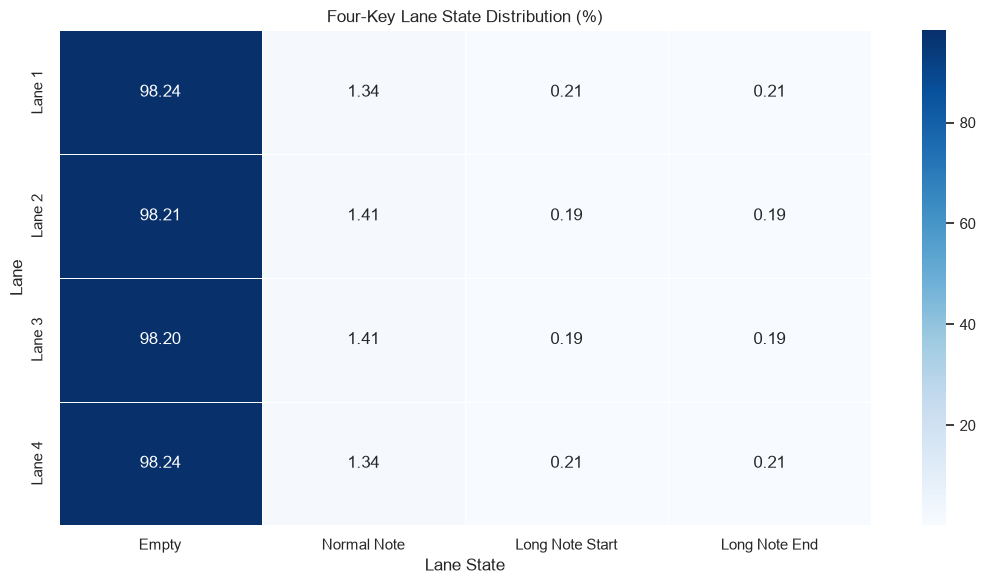

In [20]:

# ==========================================
# 11.1 LANE STATE DISTRIBUTION
# ==========================================

lane_state_percent = (
    lane_state_df.div(lane_state_df.sum(axis=1), axis=0) * 100
)

plt.figure(figsize=(11, 6))

sns.heatmap(
    lane_state_percent,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Four-Key Lane State Distribution (%)")
plt.xlabel("Lane State")
plt.ylabel("Lane")

plt.tight_layout()
plt.show()
